# Multiple Linear Regression

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What is Multiple Linear Regression?

Multiple Linear Regression models a dependent variable $y$ with **two or more independent variables** ($x_1, x_2, \dots, x_p$):

$$
y_i = \beta_0 + \beta_1 x_{i1} + \beta_2 x_{i2} + \dots + \beta_p x_{ip} + \epsilon_i
$$

- $\beta_0$ = intercept
- $\beta_j$ = coefficient for predictor $x_j$
- $\epsilon_i$ = error term

Purpose: estimate how **each predictor affects $y$ while holding the others constant**.

## 2. Matrix Formulation

$$
\mathbf{y} = \mathbf{X} \boldsymbol{\beta} + \boldsymbol{\epsilon}, \qquad
\hat{\boldsymbol{\beta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}
$$

- $\mathbf{y}$: $n \times 1$ vector of outcomes
- $\mathbf{X}$: $n \times (p+1)$ design matrix (a column of 1s for the intercept, then one column per predictor)
- $\boldsymbol{\beta}$: $(p+1) \times 1$ vector of coefficients

The inverse $(\mathbf{X}^T\mathbf{X})^{-1}$ only exists if no predictor is an exact linear combination of the others. When predictors are **perfectly collinear**, the coefficients can't be separated — and R reports `NA`.

## 3. Interpretation and Assumptions

- $\hat{\beta}_j$ is the expected change in $y$ **for a one-unit increase in $x_j$, holding all other predictors constant**.
- Assumptions: linearity, independence, homoscedasticity, normality of residuals — plus **no (severe) multicollinearity**.
- **Adjusted $R^2$** penalises adding predictors that don't help:
$$
R^2_{adj} = 1 - (1 - R^2)\frac{n - 1}{n - p - 1}
$$

## 4. A Warning First: Perfect Collinearity

If the data are designed so that sleep hours rise in lock-step with study hours, the model can't tell their effects apart.

In [2]:
study_hours <- c(2, 4, 6, 8, 10, 12, 14)
sleep_lockstep <- 5.5 + 0.25 * study_hours           # an exact linear function of study hours!
exam_scores <- c(50, 55, 65, 70, 80, 85, 90)

coef(lm(exam_scores ~ study_hours + sleep_lockstep))
cat("cor(study, sleep) =", cor(study_hours, sleep_lockstep), "-> the Sleep coefficient is NA (not estimable)\n")

(Intercept)    study_hours sleep_lockstep 
     42.857143       3.482143             NA

cor(study, sleep) = 1 -> the Sleep coefficient is NA (not estimable)


## 5. A Proper Example: Study, Sleep and Exam Scores

We now use a realistic dataset of 60 students in which study hours and sleep hours vary independently.

In [3]:
set.seed(20)
n <- 60
multi_data <- data.frame(
  Study = round(runif(n, 1, 15), 1),
  Sleep = round(runif(n, 4.5, 9), 1)
)
multi_data$Score <- round(30 + 3.0 * multi_data$Study + 4.0 * multi_data$Sleep + rnorm(n, 0, 5), 1)
head(multi_data)

multi_model <- lm(Score ~ Study + Sleep, data = multi_data)
summary(multi_model)

,Study,Sleep,Score
,<dbl>,<dbl>,<dbl>
1,13.3,6.4,95.8
2,11.8,5.0,85.1
3,4.9,8.7,77.6
4,8.4,4.7,69.6
5,14.5,8.7,114.3
6,14.7,4.7,84.6



Call:
lm(formula = Score ~ Study + Sleep, data = multi_data)

Residuals:
    Min      1Q  Median      3Q     Max 
-10.335  -3.310  -0.165   3.446  10.431 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  31.7545     3.5088   9.050 1.28e-12 ***
Study         2.9173     0.1564  18.648  < 2e-16 ***
Sleep         3.8937     0.4579   8.504 1.01e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 4.939 on 57 degrees of freedom
Multiple R-squared:  0.8757,	Adjusted R-squared:  0.8714 
F-statistic: 200.8 on 2 and 57 DF,  p-value: < 2.2e-16


In [4]:
# The OLS solution computed by hand with matrices - identical to lm()
X <- cbind(Intercept = 1, Study = multi_data$Study, Sleep = multi_data$Sleep)
y <- multi_data$Score
beta_hat <- solve(t(X) %*% X) %*% t(X) %*% y
cbind(manual = round(beta_hat[, 1], 4), lm = round(coef(multi_model), 4))

cat("\n95% confidence intervals for the coefficients:\n")
round(confint(multi_model), 3)

,manual,lm
Intercept,31.7545,31.7545
Study,2.9173,2.9173
Sleep,3.8937,3.8937



95% confidence intervals for the coefficients:


,2.5 %,97.5 %
(Intercept),24.728,38.781
Study,2.604,3.231
Sleep,2.977,4.811


**Interpretation:** holding sleep constant, each extra hour of study is associated with roughly 3 more points; holding study constant, each extra hour of sleep adds roughly 4 points. Both confidence intervals exclude 0.

## 6. Checking Multicollinearity: VIF

The **Variance Inflation Factor** measures how much a coefficient's variance is inflated by correlation with the other predictors: $VIF_j = \frac{1}{1 - R_j^2}$, where $R_j^2$ comes from regressing $x_j$ on the other predictors. Rule of thumb: VIF > 5–10 signals a problem.

In [5]:
suppressPackageStartupMessages(library(car))
vif(multi_model)

Study   Sleep 
1.00399 1.00399

## 7. Visualising the Model

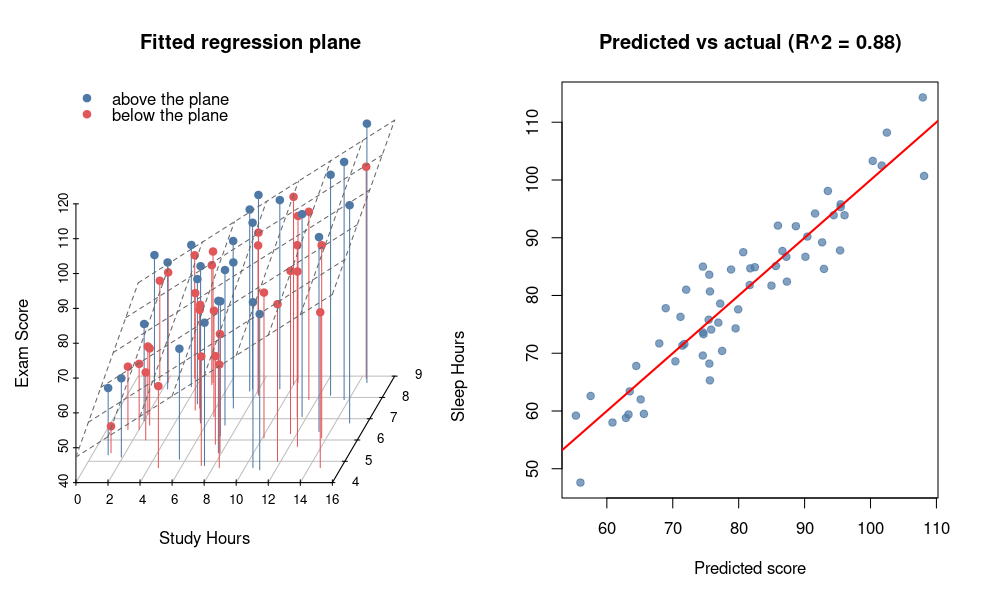

In [6]:
if (!requireNamespace("scatterplot3d", quietly = TRUE)) install.packages("scatterplot3d")
library(scatterplot3d)

par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))
s3d <- scatterplot3d(multi_data$Study, multi_data$Sleep, multi_data$Score,
                     pch = 19, color = ifelse(resid(multi_model) > 0, "#4E79A7", "#E15759"),
                     type = "h", angle = 55, box = FALSE,
                     xlab = "Study Hours", ylab = "Sleep Hours", zlab = "Exam Score",
                     main = "Fitted regression plane")
s3d$plane3d(multi_model, col = "grey40", lty = "dashed")
legend("topleft", c("above the plane", "below the plane"), col = c("#4E79A7", "#E15759"), pch = 19, bty = "n")

plot(fitted(multi_model), multi_data$Score, pch = 19, col = adjustcolor("#4E79A7", 0.7),
     main = sprintf("Predicted vs actual (R^2 = %.2f)", summary(multi_model)$r.squared),
     xlab = "Predicted score", ylab = "Actual score")
abline(0, 1, col = "red", lwd = 2)

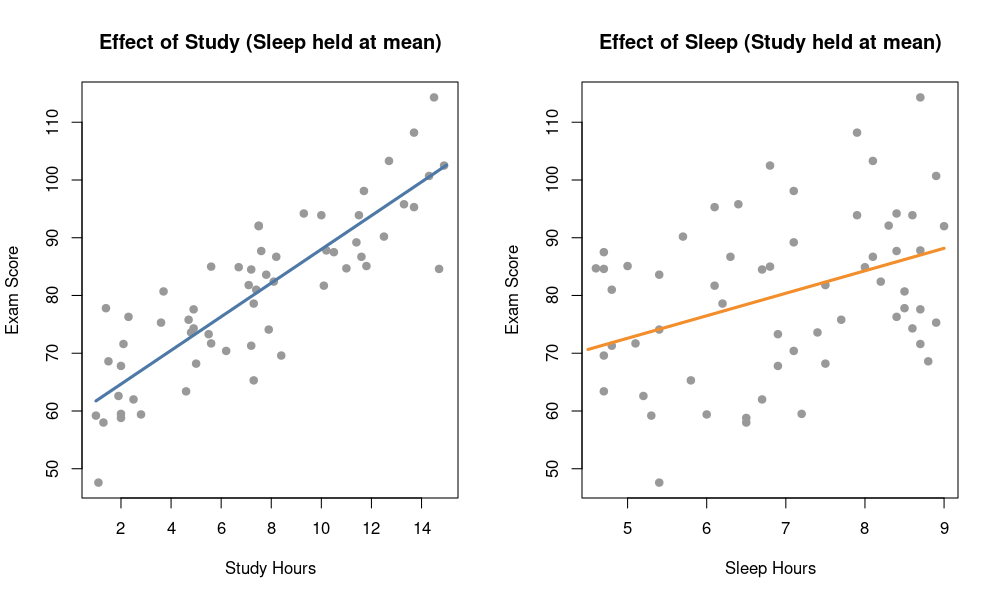

In [7]:
par(mfrow = c(1, 2))
# Partial effect of Study, holding Sleep at its mean (and vice versa)
grid_study <- data.frame(Study = seq(1, 15, length.out = 50), Sleep = mean(multi_data$Sleep))
plot(multi_data$Study, multi_data$Score, pch = 19, col = "grey60",
     main = "Effect of Study (Sleep held at mean)", xlab = "Study Hours", ylab = "Exam Score")
lines(grid_study$Study, predict(multi_model, grid_study), lwd = 3, col = "#4E79A7")

grid_sleep <- data.frame(Study = mean(multi_data$Study), Sleep = seq(4.5, 9, length.out = 50))
plot(multi_data$Sleep, multi_data$Score, pch = 19, col = "grey60",
     main = "Effect of Sleep (Study held at mean)", xlab = "Sleep Hours", ylab = "Exam Score")
lines(grid_sleep$Sleep, predict(multi_model, grid_sleep), lwd = 3, col = "#F28E2B")

## 8. Does Adding a Predictor Help?

Compare the one-predictor model to the two-predictor model with an F-test (`anova()`) and adjusted $R^2$.

In [8]:
simple_model <- lm(Score ~ Study, data = multi_data)
cat("Adjusted R^2 - Study only    :", round(summary(simple_model)$adj.r.squared, 3), "\n")
cat("Adjusted R^2 - Study + Sleep :", round(summary(multi_model)$adj.r.squared, 3), "\n\n")
anova(simple_model, multi_model)

Adjusted R^2 - Study only    : 0.713 


Adjusted R^2 - Study + Sleep : 0.871 



,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,58,3154.307,NA,NA,NA,NA
2,57,1390.373,1,1763.934,72.3146,1.007303e-11


*Insight: "Holding other variables constant" is what makes multiple regression powerful. It is also why collinear predictors are a problem: if two predictors always move together, the data contain no information about what happens when only one of them changes.*

## Real-World Use Case or Analogy

- Predicting exam scores from **study hours and sleep hours** lets you ask: *for two students who study the same amount, how much does an extra hour of sleep matter?*
- In real estate, price depends on area, location and age **together**. A simple regression on area alone mixes up the effect of size with the fact that big houses are often in expensive neighbourhoods.

Perfect collinearity is like trying to tell how much of a team's success is due to the striker when the striker and the goalkeeper have **always** played together: with no game where only one played, the data can't separate their contributions.